#LABSHEET 5

##Step 1: Import the required libraries and load a real-world image for analysis.

In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage.feature import hog
from google.colab import files

# Upload an image
uploaded = files.upload()

filename = next(iter(uploaded))
image = cv2.imread(filename)

if image is None:
    print("Error: Image could not be loaded.")
else:
    print("Image loaded successfully:", filename)

print("Name:Aman Malik")
print("CU24250099")

Saving images.jpg to images (1).jpg
Image loaded successfully: images (1).jpg
Name:Aman Malik
CU24250099


##Step 2: Convert the image into grayscale and perform basic preprocessing.

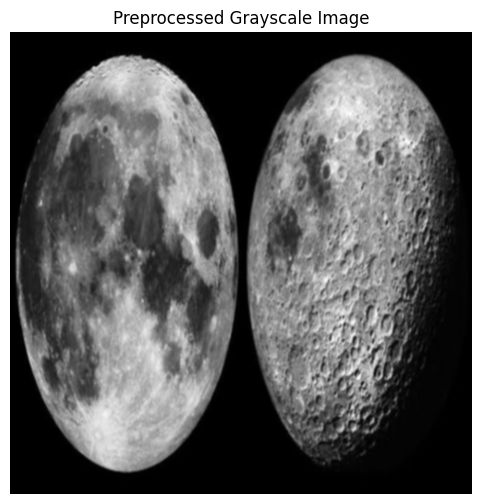

Name:Aman Malik
CU24250099


In [3]:
if image is not None:
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    # Resize the image
    gray = cv2.resize(gray, (500, 500))

    # Apply Gaussian blur
    gray_blur = cv2.GaussianBlur(gray, (3, 3), 0)

    plt.figure(figsize=(8, 6))
    plt.imshow(gray_blur, cmap="gray")
    plt.title("Preprocessed Grayscale Image")
    plt.axis("off")
    plt.show()

print("Name:Aman Malik")
print("CU24250099")

##Step 3 Apply the SIFT (Scale-Invariant Feature Transform) algorithm to detect keypoints and compute feature descriptors


In [4]:
# Create SIFT detector
sift = cv2.SIFT_create()

# Detect keypoints and compute descriptors
keypoints, descriptors = sift.detectAndCompute(gray_blur, None)

print("Number of SIFT Keypoints:", len(keypoints))

if descriptors is not None:
    print("SIFT Descriptor Shape:", descriptors.shape)
else:
    print("No descriptors found.")

print("Name:Aman Malik")
print("CU24250099")

Number of SIFT Keypoints: 2114
SIFT Descriptor Shape: (2114, 128)
Name:Aman Malik
CU24250099


##Step 4 Visualize the detected keypoints on the image and analyze their distribution across different image regions.


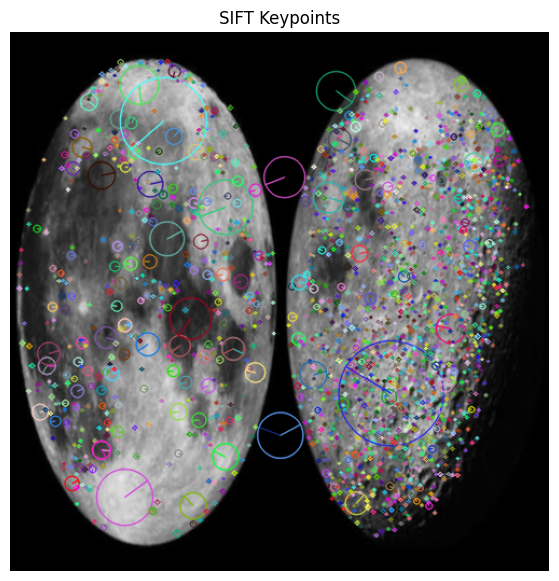

SIFT keypoints are concentrated around regions containing strong intensity changes, corners, and distinctive structures.
Name:Aman Malik
CU24250099


In [5]:
# Draw SIFT keypoints
sift_image = cv2.drawKeypoints(
    gray_blur,
    keypoints,
    None,
    flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS
)

plt.figure(figsize=(10, 7))
plt.imshow(sift_image, cmap="gray")
plt.title("SIFT Keypoints")
plt.axis("off")
plt.show()

print("SIFT keypoints are concentrated around regions containing strong intensity changes, corners, and distinctive structures.")

print("Name:Aman Malik")
print("CU24250099")

##Step 5 Extract Histogram of Oriented Gradients (HOG) features from the same image using appropriate parameters such as cell size, block size, and orientation bins


In [6]:
# Extract HOG features
hog_features, hog_image = hog(
    gray_blur,
    orientations=9,
    pixels_per_cell=(8, 8),
    cells_per_block=(2, 2),
    block_norm="L2-Hys",
    visualize=True
)

print("HOG Feature Vector Length:", len(hog_features))

print("Name:Aman Malik")
print("CU24250099")

HOG Feature Vector Length: 133956
Name:Aman Malik
CU24250099


## Step 6 Visualize the HOG descriptor to understand the gradient orientation patterns captured from the image.



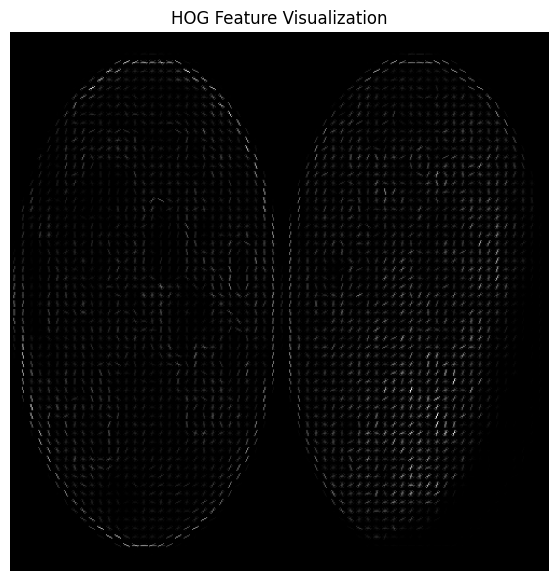

HOG represents the image using local gradient directions and magnitudes.
It is useful for describing object shapes and edges.
Name:Aman Malik
CU24250099


In [7]:
plt.figure(figsize=(10, 7))
plt.imshow(hog_image, cmap="gray")
plt.title("HOG Feature Visualization")
plt.axis("off")
plt.show()

print("HOG represents the image using local gradient directions and magnitudes.")
print("It is useful for describing object shapes and edges.")

print("Name:Aman Malik")
print("CU24250099")

## Step 7 Compare the characteristics of SIFT keypoints and HOG descriptors with respect to scale invariance, rotation invariance, and computational efficiency


In [8]:
print("Comparison of SIFT and HOG")
print("----------------------------------------")
print("SIFT:")
print("- Provides good scale invariance.")
print("- Provides good rotation invariance.")
print("- Detects distinctive local keypoints.")
print("- Computationally more expensive.")

print("\nHOG:")
print("- Mainly represents local shape and edge information.")
print("- Not inherently rotation invariant.")
print("- Less robust to large scale and rotation changes.")
print("- Generally simpler and faster than SIFT.")

print("\nConclusion:")
print("SIFT is suitable for image matching and object recognition.")
print("HOG is suitable for shape and edge-based object detection.")

print("Name:Aman Malik")
print("CU24250099")

Comparison of SIFT and HOG
----------------------------------------
SIFT:
- Provides good scale invariance.
- Provides good rotation invariance.
- Detects distinctive local keypoints.
- Computationally more expensive.

HOG:
- Mainly represents local shape and edge information.
- Not inherently rotation invariant.
- Less robust to large scale and rotation changes.
- Generally simpler and faster than SIFT.

Conclusion:
SIFT is suitable for image matching and object recognition.
HOG is suitable for shape and edge-based object detection.
Name:Aman Malik
CU24250099


## Step 8 Apply SIFT or HOG features to perform basic image matching or object recognition using two similar images.


In [9]:
from google.colab import files

# Upload two images
uploaded = files.upload()

file_names = list(uploaded.keys())

if len(file_names) < 2:
    print("Please upload two images.")
else:
    image1 = cv2.imread(file_names[0])
    image2 = cv2.imread(file_names[1])

    gray1 = cv2.cvtColor(image1, cv2.COLOR_BGR2GRAY)
    gray2 = cv2.cvtColor(image2, cv2.COLOR_BGR2GRAY)

    # Resize images
    gray1 = cv2.resize(gray1, (500, 500))
    gray2 = cv2.resize(gray2, (500, 500))

    # SIFT
    sift = cv2.SIFT_create()

    kp1, des1 = sift.detectAndCompute(gray1, None)
    kp2, des2 = sift.detectAndCompute(gray2, None)

    # BFMatcher
    bf = cv2.BFMatcher()

    matches = bf.knnMatch(des1, des2, k=2)

    # Lowe's ratio test
    good_matches = []

    for m, n in matches:
        if m.distance < 0.75 * n.distance:
            good_matches.append(m)

    # Draw matches
    matched_image = cv2.drawMatches(
        gray1,
        kp1,
        gray2,
        kp2,
        good_matches,
        None,
        flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
    )

    plt.figure(figsize=(15, 7))
    plt.imshow(matched_image, cmap="gray")
    plt.title("SIFT Image Matching")
    plt.axis("off")
    plt.show()

    print("Image 1:", file_names[0])
    print("Image 2:", file_names[1])
    print("Keypoints in Image 1:", len(kp1))
    print("Keypoints in Image 2:", len(kp2))
    print("Good Matches:", len(good_matches))

print("Aman Malik")
print("CU24250099")

Saving download (3).png to download (3).png
Please upload two images.
Aman Malik
CU24250099


##Step 9 Evaluate the strengths and limitations of both feature extraction techniques for different computer vision tasks


In [10]:
print("SIFT - Strengths")
print("----------------")
print("1. Robust to scale changes.")
print("2. Robust to rotation.")
print("3. Effective for image matching.")
print("4. Works well with distinctive local features.")

print("\nSIFT - Limitations")
print("------------------")
print("1. Computationally more expensive.")
print("2. Produces a large number of descriptors.")
print("3. Performance can decrease under major illumination or viewpoint changes.")

print("\nHOG - Strengths")
print("----------------")
print("1. Good for shape and edge representation.")
print("2. Relatively simple and efficient.")
print("3. Useful for object detection.")
print("4. Captures local gradient information effectively.")

print("\nHOG - Limitations")
print("------------------")
print("1. Not inherently rotation invariant.")
print("2. Sensitive to changes in object orientation.")
print("3. Less suitable for direct feature matching between images.")

print("Name:Aman Malik")
print("CU24250099")

SIFT - Strengths
----------------
1. Robust to scale changes.
2. Robust to rotation.
3. Effective for image matching.
4. Works well with distinctive local features.

SIFT - Limitations
------------------
1. Computationally more expensive.
2. Produces a large number of descriptors.
3. Performance can decrease under major illumination or viewpoint changes.

HOG - Strengths
----------------
1. Good for shape and edge representation.
2. Relatively simple and efficient.
3. Useful for object detection.
4. Captures local gradient information effectively.

HOG - Limitations
------------------
1. Not inherently rotation invariant.
2. Sensitive to changes in object orientation.
3. Less suitable for direct feature matching between images.
Name:Aman Malik
CU24250099


##Step 10 Document the observations and discuss suitable applications where SIFT and HOG descriptors can be effectively utilized


In [11]:
print("Observations")
print("------------")
print("1. SIFT detects important local features such as corners and distinctive regions.")
print("2. SIFT descriptors are useful for matching similar images.")
print("3. HOG describes the shape of objects using gradients and edge directions.")
print("4. HOG is useful for detecting objects with relatively stable shapes.")
print("5. SIFT is more robust to scale and rotation changes.")
print("6. HOG is generally simpler for shape-based object detection.")

print("\nSuitable Applications")
print("----------------------")
print("SIFT:")
print("- Image matching")
print("- Object recognition")
print("- Image stitching")
print("- Feature correspondence")

print("\nHOG:")
print("- Pedestrian detection")
print("- Object detection")
print("- Shape recognition")
print("- Computer vision classification tasks")

print("Name:Aman Malik")
print("CU24250099")

Observations
------------
1. SIFT detects important local features such as corners and distinctive regions.
2. SIFT descriptors are useful for matching similar images.
3. HOG describes the shape of objects using gradients and edge directions.
4. HOG is useful for detecting objects with relatively stable shapes.
5. SIFT is more robust to scale and rotation changes.
6. HOG is generally simpler for shape-based object detection.

Suitable Applications
----------------------
SIFT:
- Image matching
- Object recognition
- Image stitching
- Feature correspondence

HOG:
- Pedestrian detection
- Object detection
- Shape recognition
- Computer vision classification tasks
Name:Aman Malik
CU24250099
